In [769]:
import pandas as pd # manipulation des donnees (DataFrame)
import numpy as np # calculs numeriques
import matplotlib.pyplot as plt # graphiques
import seaborn as sns # graphiques statistiques
df = pd.read_csv("data/housing_data2 - housing_data2.csv")

In [770]:
print(df.head())

   Unnamed: 0       price    area  bedrooms  bathrooms  stories mainroad  \
0           0  13300000.0  "7420"       4.0        2.0        3      yes   
1           1  12250000.0  "8960"       4.0        4.0        4      yes   
2           2  12250000.0  "9960"       3.0        2.0        2      yes   
3           3  12215000.0  "7500"       4.0        2.0        2      yes   
4           4  11410000.0  "7420"       4.0        1.0        2      yes   

  guestroom basement hotwaterheating airconditioning  parking prefarea  \
0        no       no              no             yes        2      yes   
1        no       no              no             yes        3       no   
2        no      yes              no              no        2      yes   
3        no      yes              no             yes        3      yes   
4       yes      yes              no             yes        2       no   

  furnishingstatus  price_annuel  
0        furnished   159600000.0  
1              NaN   1470000

In [771]:
print(df.info()) 

<class 'pandas.DataFrame'>
RangeIndex: 549 entries, 0 to 548
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        549 non-null    int64  
 1   price             548 non-null    float64
 2   area              549 non-null    str    
 3   bedrooms          546 non-null    float64
 4   bathrooms         546 non-null    float64
 5   stories           549 non-null    int64  
 6   mainroad          547 non-null    str    
 7   guestroom         549 non-null    str    
 8   basement          549 non-null    str    
 9   hotwaterheating   549 non-null    str    
 10  airconditioning   549 non-null    str    
 11  parking           549 non-null    int64  
 12  prefarea          549 non-null    str    
 13  furnishingstatus  546 non-null    str    
 14  price_annuel      548 non-null    float64
dtypes: float64(4), int64(3), str(8)
memory usage: 64.5 KB
None


In [772]:
print(df.dtypes)

Unnamed: 0            int64
price               float64
area                    str
bedrooms            float64
bathrooms           float64
stories               int64
mainroad                str
guestroom               str
basement                str
hotwaterheating         str
airconditioning         str
parking               int64
prefarea                str
furnishingstatus        str
price_annuel        float64
dtype: object


In [773]:
print(df.describe())

       Unnamed: 0         price    bedrooms   bathrooms     stories  \
count  549.000000  5.480000e+02  546.000000  546.000000  549.000000   
mean   274.000000  4.779409e+06    2.967033    1.291209    1.810565   
std    158.626921  1.896038e+06    0.736227    0.515267    0.871590   
min      0.000000  1.750000e+06    1.000000    1.000000    1.000000   
25%    137.000000  3.456250e+06    2.250000    1.000000    1.000000   
50%    274.000000  4.340000e+06    3.000000    1.000000    2.000000   
75%    411.000000  5.748750e+06    3.000000    2.000000    2.000000   
max    548.000000  1.330000e+07    6.000000    4.000000    4.000000   

          parking  price_annuel  
count  549.000000  5.480000e+02  
mean     0.697632  5.735290e+07  
std      0.866875  2.275246e+07  
min      0.000000  2.100000e+07  
25%      0.000000  4.147500e+07  
50%      0.000000  5.208000e+07  
75%      1.000000  6.898500e+07  
max      3.000000  1.596000e+08  


In [774]:
df.describe(include="all").T 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,549.0,NaN,NaN,NaN,274.0,158.626921,0.0,137.0,274.0,411.0,548.0
price,548.0,NaN,NaN,NaN,4779408.649635,1896038.235454,1750000.0,3456250.0,4340000.0,5748750.0,13300000.0
area,549,284,"""6000""",24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bedrooms,546.0,NaN,NaN,NaN,2.967033,0.736227,1.0,2.25,3.0,3.0,6.0
bathrooms,546.0,NaN,NaN,NaN,1.291209,0.515267,1.0,1.0,1.0,2.0,4.0
stories,549.0,NaN,NaN,NaN,1.810565,0.87159,1.0,1.0,2.0,2.0,4.0
mainroad,547,2,yes,471,NaN,NaN,NaN,NaN,NaN,NaN,NaN
guestroom,549,2,no,452,NaN,NaN,NaN,NaN,NaN,NaN,NaN
basement,549,2,no,356,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hotwaterheating,549,2,no,524,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [775]:
df = df.drop(columns=["Unnamed: 0"]) #unnamed is just an index column, we don't need it

In [776]:
df["area"] = df["area"].astype(str).str.replace('"', '', regex=False)
df["area"] = pd.to_numeric(df["area"], errors="coerce") #area is in quotes, pandas will read it as an object instead of a number.

In [777]:
print(df.dtypes)

price               float64
area                  int64
bedrooms            float64
bathrooms           float64
stories               int64
mainroad                str
guestroom               str
basement                str
hotwaterheating         str
airconditioning         str
parking               int64
prefarea                str
furnishingstatus        str
price_annuel        float64
dtype: object


### Question 2 : Observations et traitement

**Que remarquons-nous ?**

1. **Distributions asymétriques à droite (price, area, price_annuel)** : la majorité des maisons
   sont concentrées dans les valeurs basses et une longue queue s'étend vers les valeurs élevées.
   Pour `price`, la médiane (4 340 000) est inférieure à la moyenne (≈ 4 779 000), et le max
   (13 300 000) est très éloigné de Q3 (5 748 750). Pour `area`, la médiane est 4 600, Q3 = 6 360
   mais le max atteint 16 200. Ces valeurs extrêmes sont des outliers potentiels.

2. **`price` et `price_annuel` ont exactement la même forme** : seule l'échelle change
   (price_annuel = price × 12). C'est une redondance..

3. **Attributs discrets (bedrooms, bathrooms, stories, parking)** : ce sont des comptages avec
   très peu de valeurs distinctes (histogrammes en quelques barres). La plupart des maisons ont
   3 chambres, 1 salle de bain, 1 ou 2 étages, et 0 place de parking. `bedrooms` (jusqu'à 6) et
   `bathrooms` (jusqu'à 4) ont quelques valeurs rares.

4. **Échelles très différentes** : `price_annuel` est de l'ordre de 10⁷ à 10⁸, `price` de 10⁶ à
   10⁷, `area` de 10³, alors que `bedrooms`, `bathrooms`, `stories` et `parking` vont de 0 à 6.

5. **Valeurs manquantes** : le nombre d'observations (count) n'est pas le même pour tous les
   attributs (ex. 548 pour `price`, 546 pour `bedrooms`/`bathrooms` contre 549 lignes au total).

**Quel traitement faut-il appliquer ?**

- **Supprimer `price_annuel`** (redondant avec `price`)
- **Traiter les valeurs manquantes** 
- **Analyser les outliers** des attributs asymétriques (`price`, `area`) avec les box plots, puis décider de les conserver ou non.
- **Normaliser les attributs numériques** pour les ramener à la même échelle : le Z-score car les données contiennent des outliers.
- Les attributs discrets (comptages) ne nécessitent pas de transformation particulière.

In [778]:
# liste des attributs numeriques.
num_cols = ["price", "area", "bedrooms", "bathrooms", "stories", "parking", "price_annuel"]

In [779]:
# les 5 valeurs statistiques (min, Q1, médiane, Q3, max) de chaque attribut numérique.
cinq_valeurs = df[num_cols].describe().T[["min", "25%", "50%", "75%", "max"]]
cinq_valeurs.columns = ["min", "Q1", "mediane", "Q3", "max"]
print(cinq_valeurs)

                     min           Q1     mediane          Q3          max
price          1750000.0   3456250.00   4340000.0   5748750.0   13300000.0
area              1650.0      3600.00      4600.0      6360.0      16200.0
bedrooms             1.0         2.25         3.0         3.0          6.0
bathrooms            1.0         1.00         1.0         2.0          4.0
stories              1.0         1.00         2.0         2.0          4.0
parking              0.0         0.00         0.0         1.0          3.0
price_annuel  21000000.0  41475000.00  52080000.0  68985000.0  159600000.0


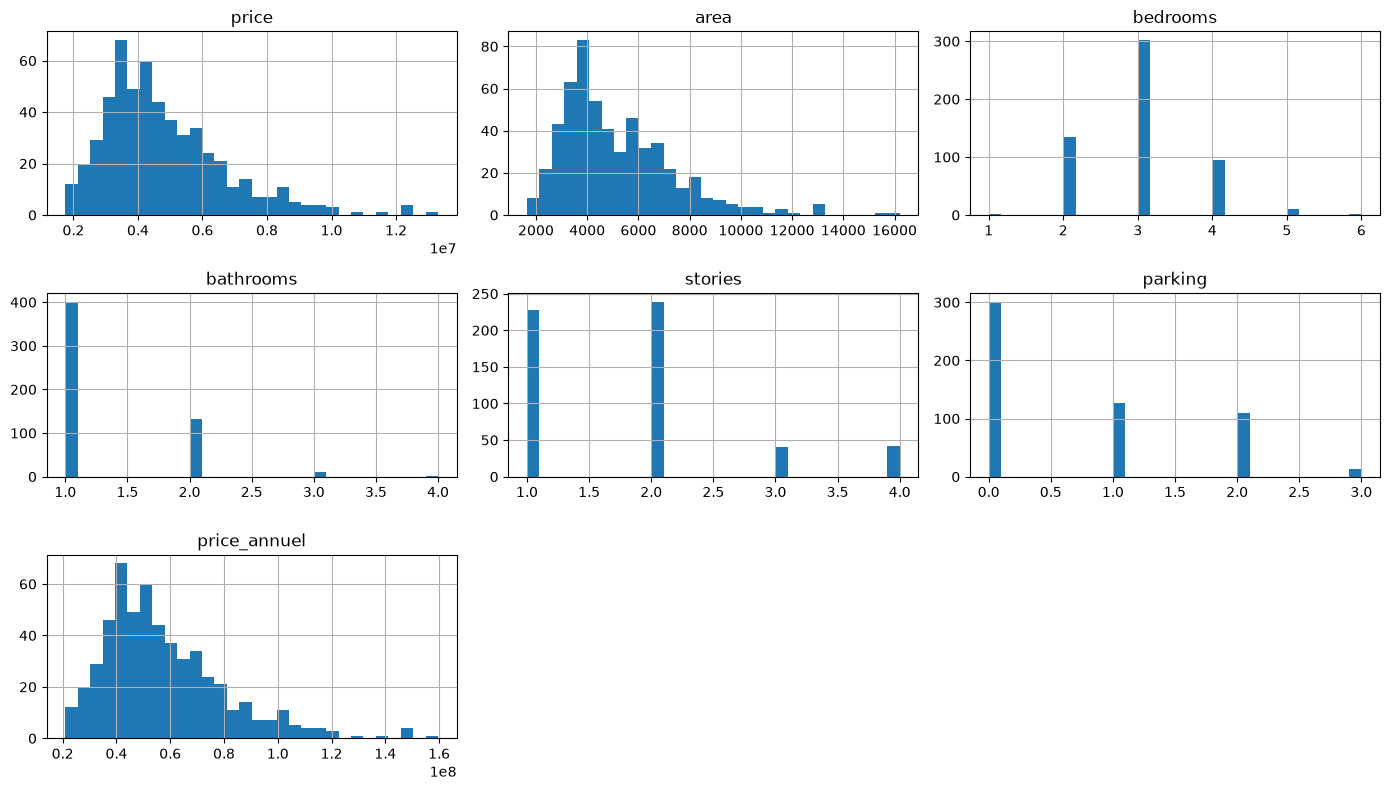

In [780]:
# Histograms.
df[num_cols].hist(bins=30, figsize=(14, 8))
plt.tight_layout()
plt.show()

### Question 3 : Matrice de corrélation

**Que remarquons-nous ?**

- `price` et `price_annuel` ont une corrélation de 1 : ils sont parfaitement corrélés. Les deux attributs contiennent exactement la même information.
- `price` est positivement corrélé avec `area` (0.55) et `bathrooms` (0.53), puis `stories`
  (0.43), `parking` (0.40) et `bedrooms` (0.37) : ce sont des corrélations moyennes.
- Entre les autres attributs, les corrélations restent faibles à moyennes (maximum 0.41 entre
  `bedrooms` et `stories`) : il n'y a pas d'autre redondance.

**Faut-il supprimer certains attributs ?**

Oui, il faut supprimer `price_annuel`. Il est redondant avec `price` (corrélation = 1). Les autres attributs sont conservés.

                 price      area  bedrooms  bathrooms   stories   parking  \
price         1.000000  0.548397  0.365744   0.533472  0.428570  0.396435   
area          0.548397  1.000000  0.153396   0.198416  0.091368  0.364238   
bedrooms      0.365744  0.153396  1.000000   0.378440  0.409860  0.148116   
bathrooms     0.533472  0.198416  0.378440   1.000000  0.338452  0.195900   
stories       0.428570  0.091368  0.409860   0.338452  1.000000  0.056887   
parking       0.396435  0.364238  0.148116   0.195900  0.056887  1.000000   
price_annuel  1.000000  0.548397  0.365744   0.533472  0.428570  0.396435   

              price_annuel  
price             1.000000  
area              0.548397  
bedrooms          0.365744  
bathrooms         0.533472  
stories           0.428570  
parking           0.396435  
price_annuel      1.000000  


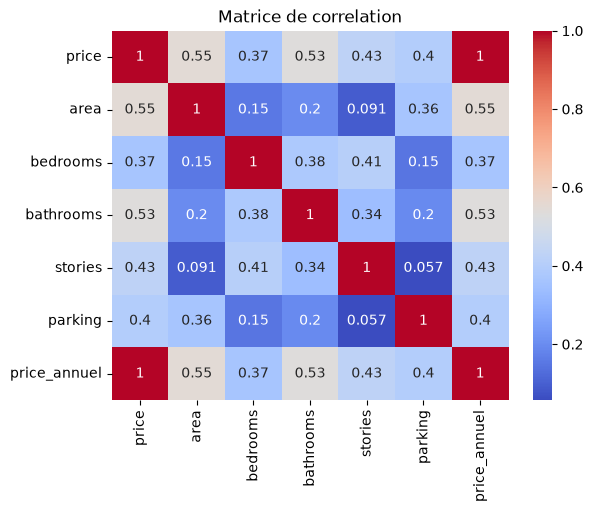

In [781]:
# Matrice de correlation
corr = df.select_dtypes(include=[np.number]).corr()
print(corr)

# heatmap annotee : proche de +1 / -1 = forte correlation
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Matrice de correlation")
plt.show()

In [782]:
# Lignes ou price est manquant mais price_annuel est connu pour recuperer price exactement.
print(df[df["price"].isna() & df["price_annuel"].notna()][["price", "price_annuel"]])

Empty DataFrame
Columns: [price, price_annuel]
Index: []


In [783]:
df = df.drop(columns=["price_annuel"])

In [784]:
# Mise a jour de la liste des attributs numeriques apres suppression de price_annuel.
num_cols = ["price", "area", "bedrooms", "bathrooms", "stories", "parking"]

### Question 5 : Attributs catégoriels

**Que remarquons-nous ?**

- Le dataset contient 7 attributs catégoriels : `mainroad`, `guestroom`, `basement`,
  `hotwaterheating`, `airconditioning`, `prefarea` (binaires) et `furnishingstatus`
  (3 modalités attendues : furnished, semi-furnished, unfurnished).
- Les attributs binaires sont déséquilibrés : par exemple `mainroad` (471 yes / 76 no)
  et `guestroom` (452 no / 97 yes).
- `mainroad` et `furnishingstatus` contiennent des valeurs manquantes.
- `furnishingstatus` contient une erreur de saisie** : la valeur `FUrnished` (2 lignes) est
  comptée comme une modalité différente de `furnished` à cause de la casse.

**Faut-il corriger certaines valeurs ?**

Oui : on corrige `FUrnished` en `furnished` avec `str.lower()`, pour que chaque modalité soit
représentée une seule fois. Sans cette correction, l'encodage one-hot créerait une colonne
inutile.

In [785]:
# Liste des attributs categoriels 
cat_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
print("Attributs categoriels :", cat_cols)

Attributs categoriels : ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']


In [786]:
# Valeurs uniques et frequences de chaque attribut categoriel.
for c in cat_cols:
    print(c, "-> valeurs uniques :", df[c].unique())
    print(df[c].value_counts())
    print()

mainroad -> valeurs uniques : <StringArray>
['yes', nan, 'no']
Length: 3, dtype: str
mainroad
yes    471
no      76
Name: count, dtype: int64

guestroom -> valeurs uniques : <StringArray>
['no', 'yes']
Length: 2, dtype: str
guestroom
no     452
yes     97
Name: count, dtype: int64

basement -> valeurs uniques : <StringArray>
['no', 'yes']
Length: 2, dtype: str
basement
no     356
yes    193
Name: count, dtype: int64

hotwaterheating -> valeurs uniques : <StringArray>
['no', 'yes']
Length: 2, dtype: str
hotwaterheating
no     524
yes     25
Name: count, dtype: int64

airconditioning -> valeurs uniques : <StringArray>
['yes', 'no']
Length: 2, dtype: str
airconditioning
no     374
yes    175
Name: count, dtype: int64

prefarea -> valeurs uniques : <StringArray>
['yes', 'no']
Length: 2, dtype: str
prefarea
no     419
yes    130
Name: count, dtype: int64

furnishingstatus -> valeurs uniques : <StringArray>
['furnished', nan, 'semi-furnished', 'FUrnished', 'unfurnished']
Length: 5, dtype: st

In [787]:
# furnishingstatus seul : la sortie precedente etait tronquee
print(df["furnishingstatus"].value_counts(dropna=False))

furnishingstatus
semi-furnished    228
unfurnished       178
furnished         138
NaN                 3
FUrnished           2
Name: count, dtype: int64


In [788]:
df["furnishingstatus"] = df["furnishingstatus"].str.lower()
print(df["furnishingstatus"].value_counts(dropna=False))

furnishingstatus
semi-furnished    228
unfurnished       178
furnished         140
NaN                 3
Name: count, dtype: int64


### Question 6 + 1 (suite de TP1) : Valeurs manquantes 

5 attributs contiennent des valeurs manquantes : `price` (1), `bedrooms` (3),
`bathrooms` (3), `mainroad` (2) et `furnishingstatus` (3), soit très peu par rapport aux
549 lignes.

**Méthode choisie et justification :**

- **Attributs numériques (`price`, `bedrooms`, `bathrooms`) : imputation par la médiane.**
  La médiane est robuste aux valeurs extrêmes. `price` est asymétrique à droite, donc la
  moyenne serait tirée vers le haut par les outliers.
- **Attributs catégoriels (`mainroad`, `furnishingstatus`) : imputation par le mode**
  (valeur la plus fréquente : `yes` et `semi-furnished`), car on ne peut pas calculer de
  moyenne ni de médiane sur du texte.
- On n'a pas supprimé les lignes : il y en a très peu et on perdrait des données utiles.

Après traitement, `isna().sum()` vaut 0 pour tous les attributs. `bedrooms` et `bathrooms`
sont reconvertis en entiers.

In [789]:
print(df.isna().sum()) # nombre de manquants par attribut

price               1
area                0
bedrooms            3
bathrooms           3
stories             0
mainroad            2
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    3
dtype: int64


In [790]:
# Imputation des attributs numeriques par la mediane (robuste aux outliers).
# price est asymetrique a droite : la moyenne serait tiree vers le haut par les valeurs extremes.
# bedrooms et bathrooms sont des comptages : la mediane donne une valeur entiere realiste.
for c in ["price", "bedrooms", "bathrooms"]:
    df[c] = df[c].fillna(df[c].median())

In [791]:
# Imputation des attributs categoriels par le mode (valeur la plus frequente), car la mediane n'a pas de sens sur du texte.
# mainroad -> "yes" (471 sur 547), furnishingstatus -> "semi-furnished" (228).
for c in ["mainroad", "furnishingstatus"]:
    df[c] = df[c].fillna(df[c].mode()[0])

In [792]:
# bedrooms et bathrooms etaient en float64 uniquement a cause des NaN.
# Plus aucun manquant : on les remet en entier (ce sont des comptages).
df["bedrooms"] = df["bedrooms"].astype(int)
df["bathrooms"] = df["bathrooms"].astype(int)

In [793]:
# Verification : plus aucun manquant
print(df.isna().sum())
print(df.dtypes)

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64
price               float64
area                  int64
bedrooms              int64
bathrooms             int64
stories               int64
mainroad                str
guestroom               str
basement                str
hotwaterheating         str
airconditioning         str
parking               int64
prefarea                str
furnishingstatus        str
dtype: object


### Question 7 : Doublons après traitement

Avant suppression, `duplicated().sum()` renvoyait 3: l'imputation des valeurs manquantes
n'a pas créé de nouveaux doublons, les 3 paires détectées étaient déjà identiques sur
tous les attributs.

Après `drop_duplicates()` (on conserve la première occurrence), il reste 0 doublon et le
dataset passe de 549 à 546 lignes.

In [794]:
# Verification des doublons apres le traitement des valeurs manquantes
print(df.duplicated().sum())

3


In [795]:
# Suppression des doublons (on garde la premiere occurrence)
df = df.drop_duplicates()
print(df.duplicated().sum()) 

0


### Question 8 : Box plots et valeurs aberrantes

**Résultats (méthode IQR, 546 lignes)**

| Attribut | Outliers | %     | Borne haute |
|----------|----------|-------|-------------|
| price    | 16       | 2,9 % | ≈ 9 191 875 |
| area     | 12       | 2,2 % | 10 500      |
| bedrooms | 14       | 2,6 % | ≈ 4         |
| bathrooms| 2        | 0,4 % | 3,5         |
| stories  | 42       | 7,7 % | 3,5         |
| parking  | 13       | 2,4 % | 2,5         |

Pour `price` et `area`, les bornes basses sont négatives : il n'y a donc aucun outlier en bas.

**Qu'est-ce qu'un outlier ?**
Une valeur qui s'écarte fortement du reste des données. Avec la règle de l'IQR, c'est une valeur
située au-delà de Q3 + 1,5 × IQR ou en dessous de Q1 − 1,5 × IQR. Sur le box plot, ce sont les
points isolés au-delà des moustaches.

**Est-ce une erreur ou une valeur réelle ?**
Ce sont des **valeurs réelles**, pas des erreurs :
- `price` (16) et `area` (12) : ce sont de grandes maisons de luxe, chères et très spacieuses.
  Aucune valeur négative, nulle ou impossible, et ces deux attributs sont liés (corrélation 0,55).
- `bedrooms`, `bathrooms`, `stories`, `parking` : ce sont des comptages à très peu de valeurs
  distinctes. Leur IQR est très étroit, donc la règle de l'IQR classe comme « outliers » des
  valeurs rares mais plausibles (maisons à 4 étages, 3 places de parking, 5 ou 6 chambres).
  C'est surtout visible pour `stories` (42 outliers, soit 7,7 %) : la règle de l'IQR est peu
  adaptée aux variables discrètes.

**Quel traitement faut-il appliquer ?**
On ne supprime pas les outliers : ils représentent de vraies maisons, et en retirer 3 % à
8 % des lignes ferait perdre de l'information. On les conserve et on applique une
normalisation adaptée à leur présence (Z-score).

In [796]:
# Les 5 valeurs de chaque attribut numerique : min, Q1, mediane, Q3, max
cinq_valeurs = df[num_cols].describe().T[["min", "25%", "50%", "75%", "max"]]
cinq_valeurs.columns = ["min", "Q1", "mediane", "Q3", "max"]
print(cinq_valeurs)

                 min          Q1    mediane         Q3         max
price      1750000.0  3438750.00  4340000.0  5740000.0  13300000.0
area          1650.0     3600.00     4600.0     6360.0     16200.0
bedrooms         1.0        2.25        3.0        3.0         6.0
bathrooms        1.0        1.00        1.0        2.0         4.0
stories          1.0        1.00        2.0        2.0         4.0
parking          0.0        0.00        0.0        1.0         3.0


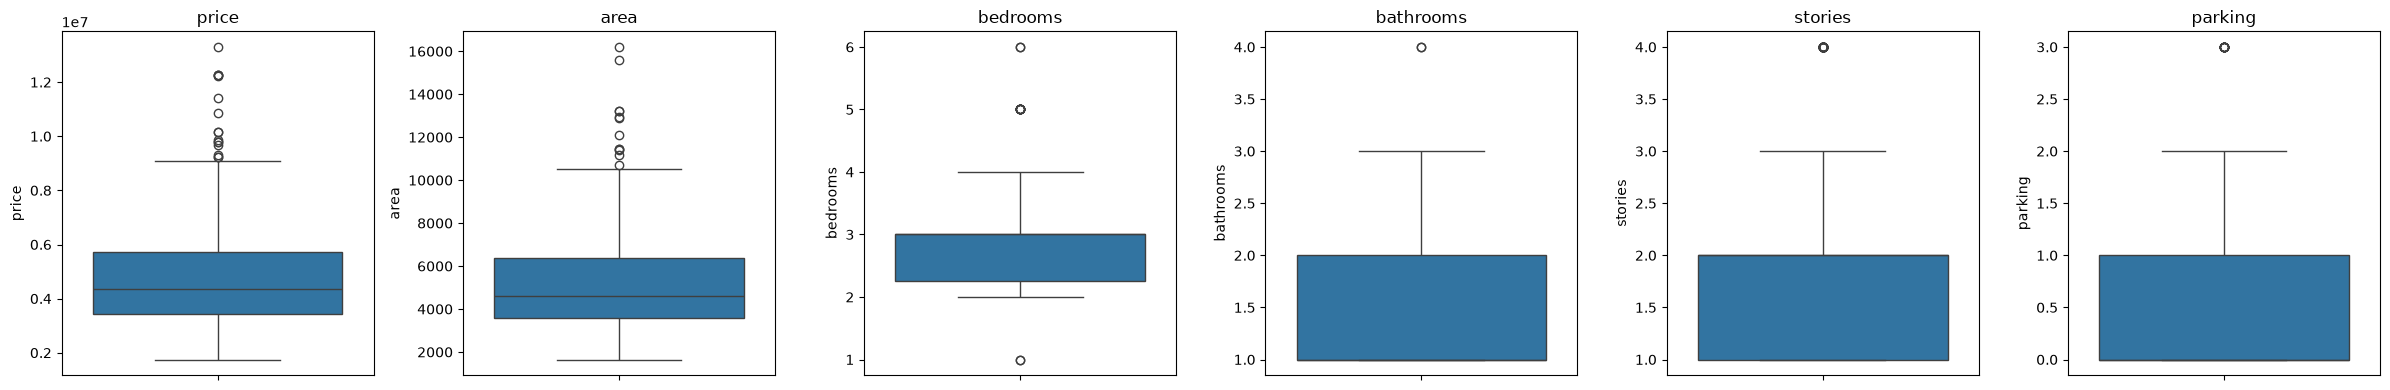

In [797]:
# Un box plot par attribut numerique 
fig, axes = plt.subplots(1, len(num_cols), figsize=(4 * len(num_cols), 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(y=df[c], ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

In [798]:
# compter les outliers (méthode IQR) : outlier si valeur < Q1 - 1.5*IQR ou valeur > Q3 + 1.5*IQR
for c in num_cols:
    Q1, Q3 = df[c].quantile(0.25), df[c].quantile(0.75)
    IQR = Q3 - Q1
    bas, haut = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n = ((df[c] < bas) | (df[c] > haut)).sum()
    print(f"{c}: {n} outliers (bornes : {bas:.0f} a {haut:.0f})")

price: 16 outliers (bornes : -13125 a 9191875)
area: 12 outliers (bornes : -540 a 10500)
bedrooms: 14 outliers (bornes : 1 a 4)
bathrooms: 2 outliers (bornes : -0 a 4)
stories: 42 outliers (bornes : -0 a 4)
parking: 13 outliers (bornes : -2 a 2)


### Question 9 : Normalisation

**Quels attributs faut-il normaliser ?**
Les attributs numériques : `price`, `area`, `bedrooms`, `bathrooms`, `stories` et `parking`.
Leurs échelles sont très différentes (`price` de l'ordre de 10⁶ à 10⁷, `area` de 10³, alors que
`bedrooms`, `bathrooms`, `stories` et `parking` vont de 0 à 6). Les attributs catégoriels ne
sont pas normalisés : une fois encodés en 0/1, ils sont déjà sur une échelle comparable.

**Quelle méthode ?**
Le **Z-score** (standardisation) : z = (x − moyenne) / écart-type.
Après transformation, chaque attribut a une moyenne ≈ 0 et un écart-type ≈ 1
(vérifié : moyennes ~10⁻¹⁶, écarts-types = 1,0009).

**Pourquoi le Z-score plutôt que le Min-Max ?**
Nous avons conservé des outliers (Q8). Avec le Min-Max, ces valeurs extrêmes fixent le min et le
max, ce qui écraserait la majorité des données dans un intervalle très étroit. Le Z-score est
moins sensible à ce problème.

**Quel est son objectif ?**
Mettre tous les attributs sur la même échelle, pour qu'un attribut aux grandes valeurs (`price`,
`area`) ne domine pas les autres dans les algorithmes basés sur des distances ou des gradients
(k-means, kNN, régression, réseaux de neurones, etc.).

In [799]:
# Z-score : moyenne ~ 0 et ecart-type ~ 1. Conseille quand il y a des outliers

from sklearn.preprocessing import StandardScaler

df_z = df.copy()
df_z[num_cols] = StandardScaler().fit_transform(df[num_cols])
print(df_z[num_cols].describe().T[["mean", "std", "min", "max"]])

                   mean       std       min       max
price      5.205441e-17  1.000917 -1.602811  4.523661
area       1.301360e-16  1.000917 -1.614673  5.083365
bedrooms  -1.821904e-16  1.000917 -2.674225  4.123385
bathrooms -2.342449e-16  1.000917 -0.565679  5.261879
stories    0.000000e+00  1.000917 -0.929450  2.514982
parking    2.602721e-17  1.000917 -0.806110  2.659527


-------------------------------------------------------- SUITE DE TP2 ----------------------------------------------------------------

In [800]:
df_suite = pd.read_csv("data/housing_data2 - housing_data2.csv")
df_suite = df_suite.drop(columns=["Unnamed: 0", "price_annuel"])
df_suite["area"] = pd.to_numeric(df_suite["area"].astype(str).str.replace('"', '', regex=False), errors="coerce")
df_suite["furnishingstatus"] = df_suite["furnishingstatus"].str.lower()
df_suite = df_suite.drop_duplicates()

manquants = df_suite.isna().sum()
print(manquants[manquants > 0])

price               1
bedrooms            3
bathrooms           3
mainroad            2
furnishingstatus    3
dtype: int64


## 1. Traitement des valeurs manquantes : identier les variables concernées et imputer selon leur type (numérique ou catégoriel).

In [801]:
from sklearn.impute import SimpleImputer

In [802]:
# Numerique -> mediane, categoriel -> mode
cols_num = ["price", "bedrooms", "bathrooms"]
cols_cat = ["mainroad", "furnishingstatus"]

In [803]:
# Mediane : robuste aux outliers
imp_num = SimpleImputer(strategy="median")
df_suite[cols_num] = imp_num.fit_transform(df_suite[cols_num])

In [804]:
# most_frequent = mode (seule option pour du texte)
imp_cat = SimpleImputer(strategy="most_frequent")
df_suite[cols_cat] = imp_cat.fit_transform(df_suite[cols_cat])

In [805]:
# bedrooms et bathrooms sont des comptages -> retour en entier
df_suite["bedrooms"] = df_suite["bedrooms"].astype(int)
df_suite["bathrooms"] = df_suite["bathrooms"].astype(int)
print(df_suite.isna().sum().sum())   # doit afficher 0

0


## 2. Traitement des variables catégorielles : identier les variables et appliquer un encodage adapté à leur nature.

In [806]:
#identifier les variables catégorielles
cat_cols = df_suite.select_dtypes(include=["object", "string"]).columns.tolist()
print(cat_cols)

['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']


In [807]:
#voir leurs modalités
for c in cat_cols:
    print(c, df_suite[c].unique())

mainroad <StringArray>
['yes', 'no']
Length: 2, dtype: str
guestroom <StringArray>
['no', 'yes']
Length: 2, dtype: str
basement <StringArray>
['no', 'yes']
Length: 2, dtype: str
hotwaterheating <StringArray>
['no', 'yes']
Length: 2, dtype: str
airconditioning <StringArray>
['yes', 'no']
Length: 2, dtype: str
prefarea <StringArray>
['yes', 'no']
Length: 2, dtype: str
furnishingstatus <StringArray>
['furnished', 'semi-furnished', 'unfurnished']
Length: 3, dtype: str


In [808]:
#ordinal pour furnishingstatus
# Ordre naturel : unfurnished < semi-furnished < furnished
ordre = {"unfurnished": 0, "semi-furnished": 1, "furnished": 2}
df_suite["furnishingstatus"] = df_suite["furnishingstatus"].map(ordre)

In [809]:
# drop_first=True : une seule colonne par yes/no (l'autre serait redondante)
bin_cols = ["mainroad", "guestroom", "basement", "hotwaterheating", "airconditioning", "prefarea"]
df_suite = pd.get_dummies(df_suite, columns=bin_cols, drop_first=True, dtype=int)

In [810]:
#verifier
print(df_suite.shape)
print(df_suite.head())
print(df_suite.dtypes)

(546, 13)
        price  area  bedrooms  bathrooms  stories  parking  furnishingstatus  \
0  13300000.0  7420         4          2        3        2                 2   
1  12250000.0  8960         4          4        4        3                 1   
2  12250000.0  9960         3          2        2        2                 1   
3  12215000.0  7500         4          2        2        3                 2   
4  11410000.0  7420         4          1        2        2                 2   

   mainroad_yes  guestroom_yes  basement_yes  hotwaterheating_yes  \
0             1              0             0                    0   
1             1              0             0                    0   
2             1              0             1                    0   
3             1              0             1                    0   
4             1              1             1                    0   

   airconditioning_yes  prefarea_yes  
0                    1             1  
1               

## 3. Traitement des Outliers : détecter les valeurs aberrantes par la méthode IQR et appliquer untraitement approprié.

In [811]:
# Seulement les variables continues. Les comptages (bedrooms, bathrooms, stories, parking)
# ont un IQR tres etroit : l'IQR y marque comme outliers des valeurs plausibles.
cols_out = ["price", "area"]

In [812]:
#détecter (méthode IQR)
for c in cols_out:
    Q1, Q3 = df_suite[c].quantile(0.25), df_suite[c].quantile(0.75)
    IQR = Q3 - Q1
    bas, haut = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n = ((df_suite[c] < bas) | (df_suite[c] > haut)).sum()
    print(f"{c}: {n} outliers (bornes : {bas:.0f} a {haut:.0f})")

price: 16 outliers (bornes : -13125 a 9191875)
area: 12 outliers (bornes : -540 a 10500)


In [813]:
# clip ramene les valeurs hors bornes aux bornes : on garde toutes les lignes.
for c in cols_out:
    Q1, Q3 = df_suite[c].quantile(0.25), df_suite[c].quantile(0.75)
    IQR = Q3 - Q1
    df_suite[c] = df_suite[c].clip(lower=Q1 - 1.5 * IQR, upper=Q3 + 1.5 * IQR)

In [814]:
#verifier que les outliers ont ete ramenees aux bornes
print(df_suite[cols_out].describe().T[["min", "max"]])

             min        max
price  1750000.0  9191875.0
area      1650.0    10500.0


## 4. Normalisation : standardiser ou normaliser Min-Max, puis comparer les échelles avant et après 

**Attributs normalisés :** `price`, `area`, `bedrooms`, `bathrooms`, `stories`, `parking`.
Les colonnes 0/1 (issues du One-Hot) et `furnishingstatus` (ordinal) ne sont pas normalisées.

**Méthode : standardisation (Z-score)**, z = (x − µ) / σ, conseillée en présence de valeurs
extrêmes. Le Min-Max est très sensible aux outliers.

**Comparaison des échelles :**
- *Avant* : échelles très différentes (`price` ~ 10⁶, `area` ~ 10³, comptages entre 0 et 4).
- *Après* : toutes les variables ont une moyenne ≈ 0 et un écart-type ≈ 1, donc comparables.
  Aucun attribut ne domine les autres dans les algorithmes basés sur les distances.

**Remarque (Data Leakage, voir Q6) :** le scaler est ici appris sur toutes les données ;
en Q6 il sera appris sur Train seulement.transformation

In [815]:
cols_norm = ["price", "area", "bedrooms", "bathrooms", "stories", "parking"]

In [816]:
avant = df_suite[cols_norm].describe().T[["mean", "std", "min", "max"]]
print(avant)

                   mean           std        min        max
price      4.726486e+06  1.743205e+06  1750000.0  9191875.0
area       5.109315e+03  2.010753e+03     1650.0    10500.0
bedrooms   2.967033e+00  7.362272e-01        1.0        6.0
bathrooms  1.291209e+00  5.152675e-01        1.0        4.0
stories    1.809524e+00  8.717698e-01        1.0        4.0
parking    6.978022e-01  8.664357e-01        0.0        3.0


In [817]:
from sklearn.preprocessing import StandardScaler

# Z-score : conseillé quand il reste des valeurs extrêmes (cf. tableau du TP)
df_std = df_suite.copy()   # copie pour garder df_suite non normalisé (utile pour Q5/Q6)
df_std[cols_norm] = StandardScaler().fit_transform(df_suite[cols_norm])

In [818]:
apres = df_std[cols_norm].describe().T[["mean", "std", "min", "max"]]
print(apres)

                   mean       std       min       max
price     -5.205441e-17  1.000917 -1.709045  2.563946
area       0.000000e+00  1.000917 -1.721986  2.683388
bedrooms  -1.821904e-16  1.000917 -2.674225  4.123385
bathrooms -2.342449e-16  1.000917 -0.565679  5.261879
stories    0.000000e+00  1.000917 -0.929450  2.514982
parking    2.602721e-17  1.000917 -0.806110  2.659527


## 5. Séparation : diviser les données en Train (80 %) et Test (20 %), puis vérier les dimensions.

La variable cible est `price`, les autres attributs sont les variables explicatives (X).
Les données sont divisées en **Train (80 %)** et **Test (20 %)** avec `train_test_split`
(`random_state=42` pour la reproductibilité).

Dimensions : Train = (436, 12), Test = (110, 12). Le Test n'est pas utilisé pour apprendre
les paramètres du prétraitement (voir Q6).

In [819]:
from sklearn.model_selection import train_test_split

In [820]:
# price = variable cible, le reste = variables explicatives
X = df_suite.drop(columns=["price"])
y = df_suite["price"]

In [821]:
# 80 % Train / 20 % Test, random_state fixe pour que le resultat soit reproductible
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [822]:
print("Train :", X_train.shape)
print("Test :", X_test.shape)

Train : (436, 12)
Test : (110, 12)


## 6. Data Leakage : identier les risques de fuite et corriger l'ordre des opérations (paramètres appris sur Train, réutilisés sur Test).
**Risques identifiés :** en Q1, Q3 et Q4, la médiane, le mode, les bornes IQR et le scaler
ont été calculés sur toutes les données avant la séparation Train/Test : des informations du
Test influençaient le prétraitement.

Autres risques : les doublons (une même maison pourrait être dans Train et Test) et la cible
`price` (imputer ou transformer `y` avec des statistiques globales).

**Correction de l'ordre des opérations :**
1. Nettoyage sans apprentissage de paramètres + suppression des doublons
2. Séparation Train (80 %) / Test (20 %)
3. Imputation : `fit` sur Train, `transform` sur Train et Test
4. Encodage (règles fixes, mêmes colonnes dans les deux ensembles)
5. Outliers : bornes IQR calculées sur Train, appliquées aux deux ensembles
6. Normalisation : `fit_transform` sur Train, `transform` sur Test

Le Test ne sert plus qu'à évaluer le modèle.

In [823]:
#rechargement, nettoyage sans apprentissage, séparation
raw = pd.read_csv("data/housing_data2 - housing_data2.csv")
raw = raw.drop(columns=["Unnamed: 0", "price_annuel"])
raw["area"] = pd.to_numeric(raw["area"].astype(str).str.replace('"', '', regex=False), errors="coerce")
raw["furnishingstatus"] = raw["furnishingstatus"].str.lower()
raw = raw.drop_duplicates()    # avant la separation : pas de meme maison dans Train et Test
raw = raw.dropna(subset=["price"])   # price = cible : on ne l'impute pas

X = raw.drop(columns=["price"])
y = raw["price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print(X_train.shape, X_test.shape)

(436, 12) (109, 12)


In [824]:
# Imputation des attributs numeriques par la mediane (robuste aux outliers).
cols_num = ["bedrooms", "bathrooms"]
cols_cat = ["mainroad", "furnishingstatus"]

imp_num = SimpleImputer(strategy="median")
X_train[cols_num] = imp_num.fit_transform(X_train[cols_num])
X_test[cols_num] = imp_num.transform(X_test[cols_num])

imp_cat = SimpleImputer(strategy="most_frequent")
X_train[cols_cat] = imp_cat.fit_transform(X_train[cols_cat])
X_test[cols_cat] = imp_cat.transform(X_test[cols_cat])

In [825]:
#encodage (règles fixes, pas d’apprentissage sur les données)
bin_cols = ["mainroad", "guestroom", "basement", "hotwaterheating", "airconditioning", "prefarea"]
ordre = {"unfurnished": 0, "semi-furnished": 1, "furnished": 2}
for d in (X_train, X_test):
    for c in bin_cols:
        d[c] = d[c].map({"yes": 1, "no": 0})
    d["furnishingstatus"] = d["furnishingstatus"].map(ordre)
    d[["bedrooms", "bathrooms"]] = d[["bedrooms", "bathrooms"]].astype(int)

In [826]:
#outliers (bornes calculées sur Train)
#La cible price n’est pas modifiée ici : on ne touche pas à y.
IQR = Q3 - Q1
bas, haut = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
X_train["area"] = X_train["area"].clip(bas, haut)
X_test["area"] = X_test["area"].clip(bas, haut)   # memes bornes que Train
Q1, Q3 = X_train["area"].quantile(0.25), X_train["area"].quantile(0.75)
IQR = Q3 - Q1
bas, haut = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
X_train["area"] = X_train["area"].clip(bas, haut)
X_test["area"] = X_test["area"].clip(bas, haut)   # memes bornes que Train

In [827]:
#normalisation (fit_transform sur Train, transform sur Test)
cols_norm = ["area", "bedrooms", "bathrooms", "stories", "parking"]
scaler = StandardScaler()
X_train[cols_norm] = scaler.fit_transform(X_train[cols_norm])
X_test[cols_norm] = scaler.transform(X_test[cols_norm])

print(X_train[cols_norm].describe().T[["mean", "std"]])
print(X_test[cols_norm].describe().T[["mean", "std"]])
print(X_train.isna().sum().sum(), X_test.isna().sum().sum())

                   mean       std
area       2.037106e-17  1.001149
bedrooms  -3.463081e-16  1.001149
bathrooms -5.296477e-17  1.001149
stories   -2.444528e-17  1.001149
parking   -6.518741e-17  1.001149
               mean       std
area       0.127928  1.128422
bedrooms   0.012278  0.918952
bathrooms -0.017754  0.988579
stories    0.089714  1.015818
parking   -0.114493  0.899021
0 0


## KNN

In [828]:
# Modeles
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
# Metriques et outils d'evaluation
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc)
from sklearn.model_selection import cross_val_score

## price est un nombre continu. Il faut donc transformer price en classes.

In [829]:
# Seuil = mediane du prix sur le TRAIN uniquement (le Test ne doit pas influencer le seuil).
seuil = y_train.median()

# 1 = maison chere (prix > seuil), 0 = maison pas chere.
y_train_cl = (y_train > seuil).astype(int)
y_test_cl = (y_test > seuil).astype(int)   # meme seuil que Train

print("Seuil :", seuil)
print(y_train_cl.value_counts())   # verifie que les 2 classes sont equilibree

Seuil : 4291000.0
price
1    218
0    218
Name: count, dtype: int64


## KNN, entraînement et prédiction

In [830]:
# k = nombre de voisins : on regarde les k maisons les plus proches et on prend la classe majoritaire.
k = 5
knn_model = KNeighborsClassifier(n_neighbors=k)

# fit : KNN memorise simplement les donnees du Train (pas de vrai calcul a ce stade).
knn_model.fit(X_train, y_train_cl)

# predict : pour chaque maison du Test, trouve ses 5 voisins dans le Train et vote.
y_pred_knn = knn_model.predict(X_test)

## métriques KNN

In [831]:
# accuracy  = % de bonnes predictions
# precision = parmi les "cheres" predites, combien le sont vraiment
# recall    = parmi les vraies "cheres", combien ont ete trouvees
# f1        = compromis entre precision et recall
print("Accuracy :", accuracy_score(y_test_cl, y_pred_knn))
print("Precision :", precision_score(y_test_cl, y_pred_knn))
print("Recall :", recall_score(y_test_cl, y_pred_knn))
print("F1-score :", f1_score(y_test_cl, y_pred_knn))

Accuracy : 0.7889908256880734
Precision : 0.8490566037735849
Recall : 0.75
F1-score : 0.7964601769911505


## matrice de confusion KNN

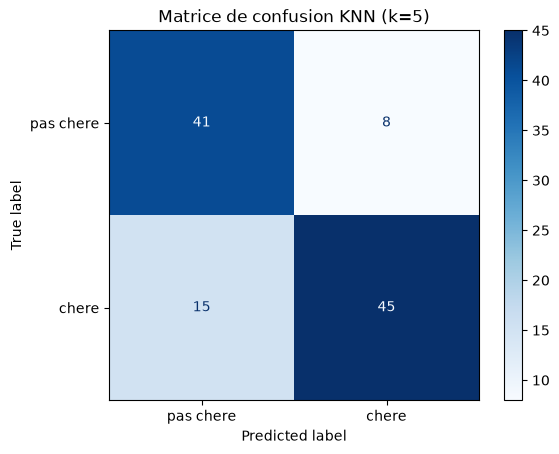

In [832]:
# Diagonale = bonnes predictions. Hors diagonale = erreurs (faux positifs / faux negatifs).
cm = confusion_matrix(y_test_cl, y_pred_knn)
ConfusionMatrixDisplay(cm, display_labels=["pas chere", "chere"]).plot(cmap="Blues")
plt.title(f"Matrice de confusion KNN (k={k})")
plt.show()

## courbe ROC KNN

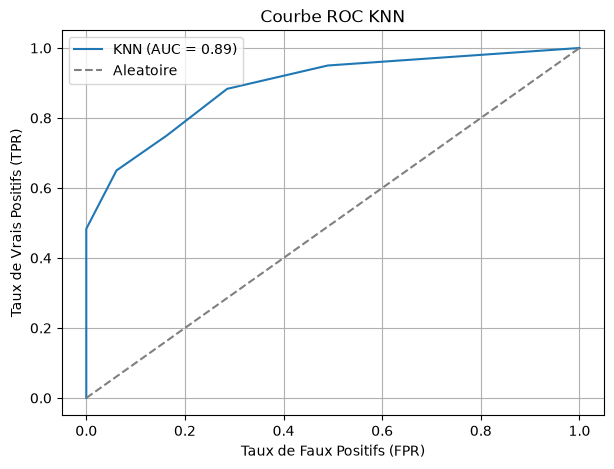

In [833]:
# predict_proba donne la probabilite d'etre de classe 1 (chere) pour chaque maison.
y_score = knn_model.predict_proba(X_test)[:, 1]

# FPR/TPR pour tous les seuils de decision possibles.
fpr, tpr, _ = roc_curve(y_test_cl, y_score)
roc_auc = auc(fpr, tpr)   # aire sous la courbe : 1 = parfait, 0.5 = hasard

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"KNN (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Aleatoire")   # reference : hasard
plt.xlabel("Taux de Faux Positifs (FPR)")
plt.ylabel("Taux de Vrais Positifs (TPR)")
plt.title("Courbe ROC KNN")
plt.legend()
plt.grid(True)
plt.show()

## précision en fonction de k

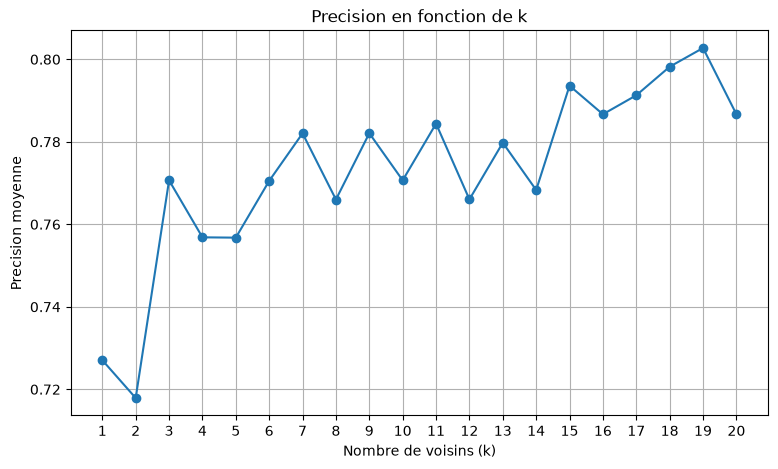

In [834]:
# On teste k = 1 a 20 et on garde la precision moyenne en validation croisee (5 plis sur le Train).
# On utilise le Train seulement : le Test reste intact pour l'evaluation finale.
k_values = range(1, 21)
accuracies = []
for k_i in k_values:
    scores = cross_val_score(KNeighborsClassifier(n_neighbors=k_i), X_train, y_train_cl, cv=5, scoring="accuracy")
    accuracies.append(scores.mean())

plt.figure(figsize=(9, 5))
plt.plot(k_values, accuracies, marker="o")
plt.xticks(k_values)
plt.xlabel("Nombre de voisins (k)")
plt.ylabel("Precision moyenne")
plt.title("Precision en fonction de k")
plt.grid(True)
plt.show()